# 8. Interpretabilidad

Se explica el MLP de scikit-learn `(100,)` con hash12, entrenado con 10 millones de filas (semilla 42). Este capítulo
responde P4: ¿son las explicaciones de LIME estables y fieles al modelo?

**El espacio interpretable.** Con hashing, las 4.100 columnas del modelo no se pueden leer. Los explicadores no las
tocan. Perturban los códigos de las 23 variables originales, y una función hace el resto del camino:

`códigos originales → numéricas reconstruidas → hashing y escalado → MLP → probabilidad`

Esa función, `predict_codes` en `scripts/06_interpret.py`, es la correspondencia pedida en el enunciado. Una consecuencia:
cada explicación habla de "este `site_id` frente a otro valor", no de una columna hasheada.

**Selección de casos.** 10 falsos positivos y 10 falsos negativos de mayor confianza errónea, del día 29, para no volver a
usar la prueba.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from ctr.plots import C, style, es
from ctr.config import RES
style()
I = RES / "interp"
ca = pd.read_csv(I / "casos.csv"); l = pd.read_csv(I / "lime.csv"); st = pd.read_csv(I / "lime_estabilidad.csv")
se = pd.read_csv(I / "lime_sensibilidad.csv"); sh = pd.read_csv(I / "shap_casos.csv"); sg = pd.read_csv(I / "shap_global.csv"); pm = pd.read_csv(I / "permutacion.csv")
cols = [c[2:] for c in l.columns if c.startswith("w_")]
ca.groupby("tipo").agg(casos=("i", "size"), p_min=("p", "min"), p_max=("p", "max")).round(3)

,casos,p_min,p_max
tipo,,,
FN,10,0.001,0.002
FP,10,0.935,0.976


## 8.1 Explicaciones locales

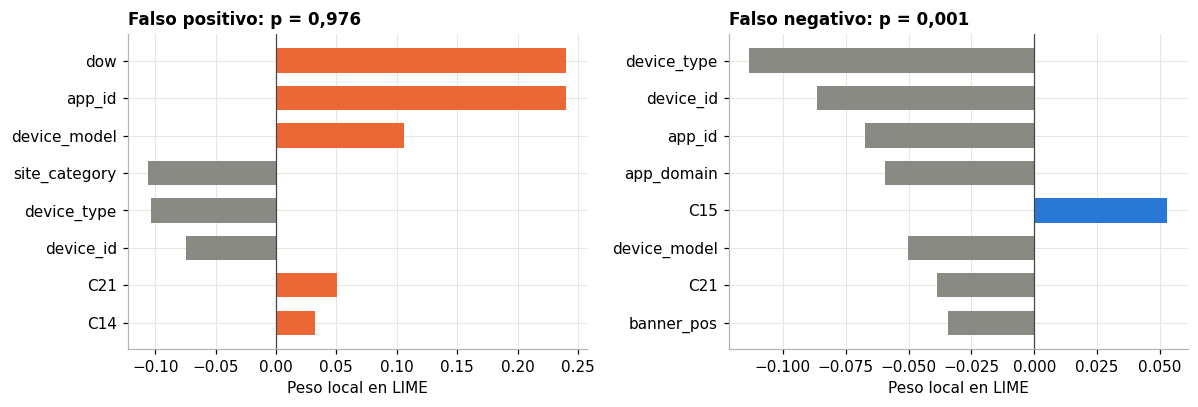

In [2]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, t, co in zip(ax, ("FP", "FN"), (C["naranja"], C["azul"])):
    d = l[(l.tipo == t) & (l.i == l[l.tipo == t].i.iloc[0]) & (l.seed == 42)]
    w = d[[f"w_{c}" for c in cols]].iloc[0].dropna().rename(lambda x: x[2:]).sort_values(key=abs).tail(8)
    a.barh(w.index, w.values, color=[co if v > 0 else C["gris"] for v in w.values], height=.65)
    a.axvline(0, color="#444", lw=.8)
    pr = ca[ca.i == d.i.iloc[0]].p.iloc[0]
    a.set(title=f"{'Falso positivo' if t == 'FP' else 'Falso negativo'}: p = {es(pr, 3)}", xlabel="Peso local en LIME")
plt.tight_layout(); plt.show()

## 8.2 Fidelidad: R² del sustituto local

In [3]:
f = l.groupby("tipo").agg(R2_media=("r2", "mean"), R2_mediana=("r2", "median"), R2_min=("r2", "min"), R2_max=("r2", "max")).round(3)
l["err"] = (l.local_pred - l.f).abs()
f["|sustituto - modelo|"] = l.groupby("tipo").err.mean().round(3)
f

,R2_media,R2_mediana,R2_min,R2_max,|sustituto - modelo|
tipo,,,,,
FN,0.286,0.281,0.183,0.358,0.046
FP,0.307,0.310,0.240,0.342,0.174


## 8.3 Estabilidad: Jaccard del top 5 entre semillas

In [4]:
s5 = st.groupby("tipo").j5.agg(["mean", "min", "max"]).round(3)
print("Jaccard por caso, media:", es(st.groupby("i").j5.mean().mean(), 3))
s5

Jaccard por caso, media: 0,736


,mean,min,max
tipo,,,
FN,0.729,0.429,1.0
FP,0.744,0.250,1.0


## 8.4 Sensibilidad al kernel y a las muestras perturbadas

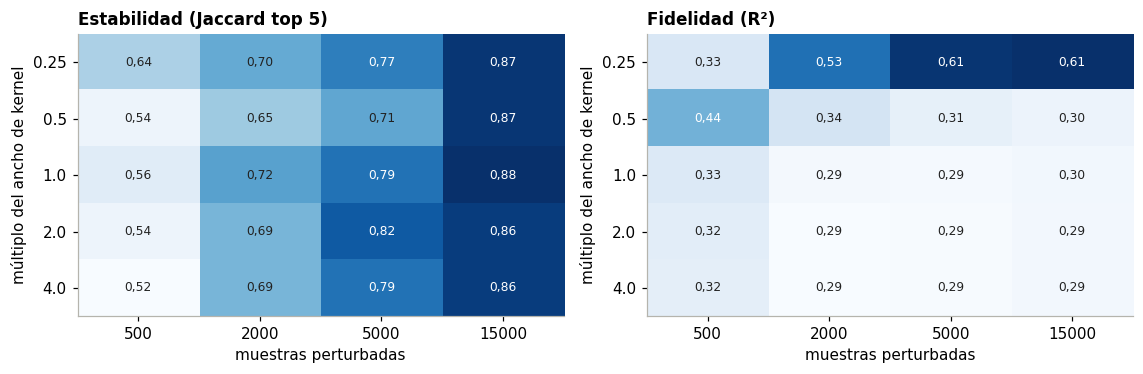

In [5]:
p1 = se.groupby(["kw", "ns"]).j5.mean().unstack(); p2 = se.groupby(["kw", "ns"]).r2.mean().unstack()
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.5))
for a, p, t in zip(ax, (p1, p2), ("Estabilidad (Jaccard top 5)", "Fidelidad (R²)")):
    im = a.imshow(p.values, cmap="Blues", aspect="auto")
    a.set_xticks(range(p.shape[1]), p.columns); a.set_yticks(range(p.shape[0]), p.index); a.grid(False)
    a.set(title=t, xlabel="muestras perturbadas", ylabel="múltiplo del ancho de kernel")
    for i in range(p.shape[0]):
        for j in range(p.shape[1]):
            a.text(j, i, f"{p.values[i, j]:.2f}".replace(".", ","), ha="center", va="center", fontsize=8, color="white" if p.values[i, j] > p.values.mean() else "#222")
plt.tight_layout(); plt.show()

## 8.5 Contraste con SHAP e importancia por permutación

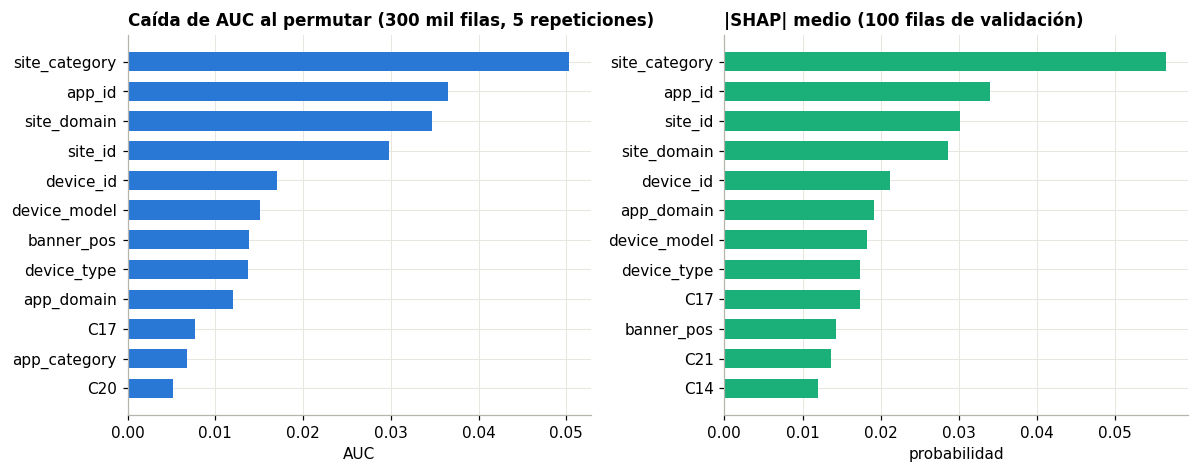

,Permutación,SHAP,LIME
Permutación,1.00,0.93,0.2
SHAP,0.93,1.00,0.3
LIME,0.20,0.30,1.0


In [6]:
g = pd.DataFrame({"SHAP": sg[cols if set(cols) <= set(sg.columns) else sg.columns].abs().mean()})
g = g.join(pm.set_index("col").caida_auc.rename("Permutación"), how="outer")
lm = l[[f"w_{c}" for c in cols]].abs().mean().rename(lambda x: x[2:]).rename("LIME"); g = g.join(lm, how="outer")
g = g.sort_values("Permutación", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
d = g.dropna(subset=["Permutación"]).head(12).iloc[::-1]
ax[0].barh(d.index, d["Permutación"], color=C["azul"], height=.65); ax[0].set(title="Caída de AUC al permutar (300 mil filas, 5 repeticiones)", xlabel="AUC")
d2 = g.dropna(subset=["SHAP"]).sort_values("SHAP").tail(12)
ax[1].barh(d2.index, d2.SHAP, color=C["aqua"], height=.65); ax[1].set(title="|SHAP| medio (100 filas de validación)", xlabel="probabilidad")
plt.tight_layout(); plt.show()
g[["Permutación", "SHAP", "LIME"]].corr(method="spearman").round(2)

In [7]:
def top(s, k=5): return set(s.abs().sort_values(ascending=False).index[:k])
filas = []
for _, c in ca.iterrows():
    a = sh[sh.i == c.i][cols if set(cols) <= set(sh.columns) else [x for x in sh.columns if x not in ("i", "tipo")]].iloc[0]
    b = l[(l.i == c.i) & (l.seed == 42)][[f"w_{x}" for x in cols]].iloc[0].dropna().rename(lambda x: x[2:])
    A, B = top(a), top(b)
    filas.append(dict(i=c.i, tipo=c.tipo, jaccard=len(A & B) / len(A | B)))
co = pd.DataFrame(filas)
print("Coherencia LIME y SHAP, Jaccard top 5:", es(co.jaccard.mean(), 3))
co.groupby("tipo").jaccard.mean().round(3)

Coherencia LIME y SHAP, Jaccard top 5: 0,191


tipo
FN    0.119
FP    0.262
Name: jaccard, dtype: float64

## 8.6 Respuesta a P4

**LIME no es fiel en este modelo, y su estabilidad depende de cómo se configure.**

- **Fidelidad baja.** Con los parámetros por defecto, el sustituto lineal explica cerca del 30 % de la variación local del
  MLP (R² medio 0,29 en FN y 0,31 en FP). Al estrechar el kernel a un cuarto del ancho por defecto, R² sube a 0,61. Es lo
  esperable: un MLP con hashing no es lineal en un vecindario amplio.
- **Estabilidad moderada y comprable.** Con 5.000 muestras, el top 5 coincide en promedio un 73 % entre semillas (Jaccard).
  Con 15.000 muestras llega a 0,87. Con 500 cae a 0,54. La estabilidad se compra con muestras, no con el kernel.
- **Incoherente con SHAP.** El top 5 de LIME y el de KernelSHAP comparten 19 % de las variables por caso. En lo global, SHAP
  y la permutación coinciden casi por completo (Spearman 0,93), y LIME queda solo (0,20 y 0,30).

La causa de la discrepancia está en cómo LIME perturba categóricas: sustituye cada variable por otro valor tomado de la
distribución de entrenamiento y pesa por cercanía en un espacio binario de "igual o distinto". Así, `dow`, `hod` y
`device_ip` reciben pesos altos. Cambiar el miércoles por otro día, o una IP por otra cualquiera, mueve la predicción,
aunque esas variables pesen poco cuando se permutan de verdad en la población.

**La lectura útil viene de SHAP y la permutación:** el contexto de publicación manda. `site_category`, `app_id`,
`site_domain` y `site_id` encabezan ambas listas, seguidos de `device_id` y `device_model`. Los campos anónimos pesan
poco una vez que el modelo conoce sitio y app, aunque `C17` y `C14` tenían alta información mutua en el EDA: comparten
información con ellos.

**Qué no garantiza LIME:** ni que la explicación describa el modelo (R² bajo), ni que sea única (depende de la semilla), ni que
respete dependencias entre variables. Perturba `site_id` sin ajustar `site_domain`, y crea combinaciones que no existen.

**Una advertencia sobre la función explicada.** En el modelo real, la actividad de una IP no vista vale 0, un valor que en
entrenamiento nunca aparece. Para perturbar códigos hay que fijar la actividad de las filas raras, y aquí se usó su media real
en entrenamiento. Esa función reconstruida tiene AUC 0,747 en el día 29, contra 0,740 del modelo. La diferencia sugiere que
la numérica de actividad sufre con IP nuevas: queda como trabajo futuro, y la explicación describe un pariente cercano del
modelo, no el modelo exacto.